# Gaming and Mental Health Dataset Analysis

Exploratory Data Analysis (EDA) of a large dataset about gaming behavior and mental health.

Dataset source:
https://www.kaggle.com/datasets/sharmajicoder/gaming-and-mental-health

## 1- Problem Statement

Video games are a major form of entertainment worldwide, but their potential impact on mental health has become an important topic of discussion.

This project analyzes the **Gaming and Mental Health dataset** obtained from Kaggle. The dataset contains information about players’ gaming habits, lifestyle variables, and mental health indicators such as stress, anxiety, depression, and addiction levels.

The goal of this analysis is to explore whether gaming behavior — particularly daily gaming hours — shows any meaningful relationship with mental health metrics and lifestyle factors.

Through exploratory data analysis (EDA), we aim to identify patterns, correlations, and potential insights within the dataset.

## 2- Import libraries and Download dataset

Import the necessary Python libraries for data loading and analysis.

In [4]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from google.colab import drive

# 1. Montar Google Drive
drive.mount('/content/drive')

# 2. Ruta exacta al archivo en tu Drive
file_path = (
    '/content/drive/MyDrive/Colab'
    ' Notebooks/Gaming_Mental_Health_Analysis/gaming_mental_health_10M_40features.csv'
)

# 3. Lectura del dataset
# Nota: Son 10 millones de filas. Si la RAM de Colab se satura, usa nrows=500_000 para una muestra representativa.
df = pd.read_csv(file_path)

print(
    f"Dataset cargado con éxito: {df.shape[0]:,} registros y {df.shape[1]}"
    ' variables.'
)
df.head()

Mounted at /content/drive
Dataset cargado con éxito: 1,000,000 registros y 39 variables.


,age,gender,income,daily_gaming_hours,weekly_sessions,years_gaming,sleep_hours,caffeine_intake,exercise_hours,stress_level,...,parental_supervision,loneliness_score,aggression_score,happiness_score,bmi,screen_time_total,eye_strain_score,back_pain_score,competitive_rank,internet_quality
0,51,Female,8615,3.68,22,17,5.26,1.00,0.18,3,...,0,2.87,3.19,5.20,19.69,4.71,5.71,4.81,80,10
1,41,Female,39453,5.70,34,16,9.20,0.70,1.44,8,...,7,4.17,7.73,5.40,26.37,6.62,6.77,3.99,57,2
2,27,Male,40466,1.58,8,22,7.39,2.24,3.15,3,...,9,9.38,2.85,5.17,25.15,9.30,2.16,4.75,59,10
3,55,Male,51076,6.11,39,24,7.99,1.65,2.80,1,...,5,8.24,7.19,8.62,26.42,13.81,4.72,5.37,89,1
4,20,Male,86116,3.65,17,0,7.12,1.02,1.01,2,...,9,6.65,2.53,9.71,25.75,10.74,3.90,6.44,15,10


## 3- Initial Data Exploration

In this section we explore the structure of the dataset, including its size, columns, data types, and basic statistics. This helps us understand the data before performing deeper analysis.

### 3.1 Dataset Size

Check the number of rows and columns in the dataset.

In [ ]:
df.shape

(1000000, 39)

In [ ]:
df.columns

Index(['age', 'gender', 'income', 'daily_gaming_hours', 'weekly_sessions',
       'years_gaming', 'sleep_hours', 'caffeine_intake', 'exercise_hours',
       'stress_level', 'anxiety_score', 'depression_score',
       'social_interaction_score', 'relationship_satisfaction',
       'academic_performance', 'work_productivity', 'addiction_level',
       'multiplayer_ratio', 'toxic_exposure', 'violent_games_ratio',
       'mobile_gaming_ratio', 'night_gaming_ratio', 'weekend_gaming_hours',
       'friends_gaming_count', 'online_friends', 'streaming_hours',
       'esports_interest', 'headset_usage', 'microtransactions_spending',
       'parental_supervision', 'loneliness_score', 'aggression_score',
       'happiness_score', 'bmi', 'screen_time_total', 'eye_strain_score',
       'back_pain_score', 'competitive_rank', 'internet_quality'],
      dtype='object')

### 3.2 Dataset Structure

Inspect the data types and memory usage of the dataset.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 39 columns):
 #   Column                      Non-Null Count    Dtype  
---  ------                      --------------    -----  
 0   age                         1000000 non-null  int64  
 1   gender                      1000000 non-null  object 
 2   income                      1000000 non-null  int64  
 3   daily_gaming_hours          1000000 non-null  float64
 4   weekly_sessions             1000000 non-null  int64  
 5   years_gaming                1000000 non-null  int64  
 6   sleep_hours                 1000000 non-null  float64
 7   caffeine_intake             1000000 non-null  float64
 8   exercise_hours              1000000 non-null  float64
 9   stress_level                1000000 non-null  int64  
 10  anxiety_score               1000000 non-null  float64
 11  depression_score            1000000 non-null  float64
 12  social_interaction_score    1000000 non-null  float64
 13

### 3.3 Basic Statistics

Generate summary statistics for numerical columns.

In [ ]:
df.describe()

,age,income,daily_gaming_hours,weekly_sessions,years_gaming,sleep_hours,caffeine_intake,exercise_hours,stress_level,anxiety_score,...,parental_supervision,loneliness_score,aggression_score,happiness_score,bmi,screen_time_total,eye_strain_score,back_pain_score,competitive_rank,internet_quality
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.00000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,...,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,35.986005,77497.675955,3.999255,19.997540,12.002512,7.00053,1.997513,1.999008,5.497577,4.998644,...,4.996374,4.998520,5.000455,5.981822,24.003916,8.002032,4.998675,4.018777,49.448122,5.503339
std,13.557163,41851.540503,2.826307,11.253438,7.207838,1.50111,1.996174,1.999545,2.873248,1.977711,...,3.160810,1.977601,1.980307,1.956122,3.999927,3.998987,1.979308,1.956123,28.873153,2.871940
min,13.000000,5000.000000,0.000000,1.000000,0.000000,-0.17000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,4.450000,0.070000,0.000000,0.000000,0.000000,1.000000
25%,24.000000,41258.000000,1.920000,10.000000,6.000000,5.99000,0.580000,0.580000,3.000000,3.650000,...,2.000000,3.650000,3.650000,4.650000,21.300000,5.070000,3.650000,2.660000,24.000000,3.000000
50%,36.000000,77521.000000,3.360000,20.000000,12.000000,7.00000,1.390000,1.390000,5.000000,5.000000,...,5.000000,5.000000,5.000000,6.000000,24.000000,7.350000,5.000000,4.000000,49.000000,6.000000
75%,48.000000,113697.000000,5.380000,30.000000,18.000000,8.01000,2.770000,2.770000,8.000000,6.350000,...,8.000000,6.350000,6.350000,7.350000,26.700000,10.220000,6.350000,5.350000,74.000000,8.000000
max,59.000000,149999.000000,30.420000,39.000000,24.000000,14.02000,26.900000,26.480000,10.000000,10.000000,...,10.000000,10.000000,10.000000,10.000000,43.600000,46.600000,10.000000,10.000000,99.000000,10.000000


### 3.4 Random Sample of the Dataset

Display a few random rows to better understand the data.

In [ ]:
df.sample(5) # filas aleatorias

,age,gender,income,daily_gaming_hours,weekly_sessions,years_gaming,sleep_hours,caffeine_intake,exercise_hours,stress_level,...,parental_supervision,loneliness_score,aggression_score,happiness_score,bmi,screen_time_total,eye_strain_score,back_pain_score,competitive_rank,internet_quality
297567,14,Female,85478,7.97,6,14,9.35,2.94,3.38,8,...,2,4.52,7.74,10.00,25.77,9.73,4.77,0.00,91,6
139231,24,Male,145449,3.53,31,21,7.04,5.56,3.65,7,...,5,1.96,7.51,6.62,24.07,5.90,4.50,4.35,11,3
601671,47,Female,127262,4.33,8,12,7.78,3.55,1.04,8,...,3,6.92,5.33,8.02,26.54,5.38,6.49,3.33,49,7
257175,39,Male,135606,4.24,15,20,5.33,0.12,1.66,6,...,7,4.92,7.66,3.43,23.37,7.24,7.11,2.41,48,4
988750,18,Female,101984,2.76,25,19,5.57,1.17,2.26,8,...,8,5.72,6.04,7.26,17.19,4.28,3.08,3.59,33,6


### 3.5 Missing Values

Check for missing values in each column.

In [ ]:
df.isnull().sum()

,0
age,0
gender,0
income,0
daily_gaming_hours,0
weekly_sessions,0
years_gaming,0
sleep_hours,0
caffeine_intake,0
exercise_hours,0
stress_level,0


### 3.6 Explore Key Variables

Inspect distributions of important variables such as gender and age.

In [ ]:
df["gender"].value_counts()

,count
gender,
Male,480581
Female,479579
Other,39840


In [ ]:
# df["age"].unique()
# sorted(df["age"].unique())
df["age"].value_counts().sort_index()

,count
age,
13,21291
14,21067
15,21355
16,21367
17,21569
18,21089
19,21170
20,21240
21,21134


## 4- Data Distribution Analysis
Understanding how key variables are distributed

### 4.1 Create a Smaller Sample for Faster Exploration

Create a smaller subset of the dataset for quicker experimentation and analysis.

In [ ]:
df_sample = df.sample(10000, random_state=42)
df_sample

,age,gender,income,daily_gaming_hours,weekly_sessions,years_gaming,sleep_hours,caffeine_intake,exercise_hours,stress_level,...,parental_supervision,loneliness_score,aggression_score,happiness_score,bmi,screen_time_total,eye_strain_score,back_pain_score,competitive_rank,internet_quality
987231,45,Female,128362,6.78,30,3,8.12,3.54,1.95,10,...,5,4.06,7.15,5.70,23.42,14.00,4.84,3.74,37,3
79954,52,Female,52700,6.24,19,22,7.79,0.69,5.33,9,...,0,7.06,6.27,6.95,21.87,8.98,5.17,6.75,31,3
567130,50,Female,94907,1.07,6,8,6.70,1.57,0.68,9,...,3,4.72,1.01,8.48,22.65,5.57,4.09,3.11,86,8
500891,27,Male,94803,10.31,14,19,3.19,0.32,1.37,7,...,2,4.69,5.64,3.86,24.58,12.01,4.67,2.81,58,8
55399,44,Male,73264,1.73,10,7,6.15,1.38,1.76,5,...,6,4.49,1.24,8.14,23.84,10.58,3.15,3.50,97,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
686403,20,Female,149465,1.86,28,13,9.15,1.27,2.99,3,...,0,6.39,1.63,5.01,22.69,2.94,3.95,4.21,72,2
100678,50,Female,71057,0.34,9,14,8.92,0.49,0.09,4,...,2,2.11,5.25,6.92,17.53,6.80,7.66,3.80,87,3
488468,37,Female,135605,2.68,8,17,5.79,0.33,0.75,7,...,3,4.78,5.82,9.59,23.54,4.13,6.63,6.68,71,2
583782,20,Female,8550,1.04,34,23,7.56,0.78,0.76,3,...,6,3.00,4.29,0.46,21.81,2.06,5.19,2.14,55,5


### 4.2 Age Distribution
Analyze the distribution of players' ages

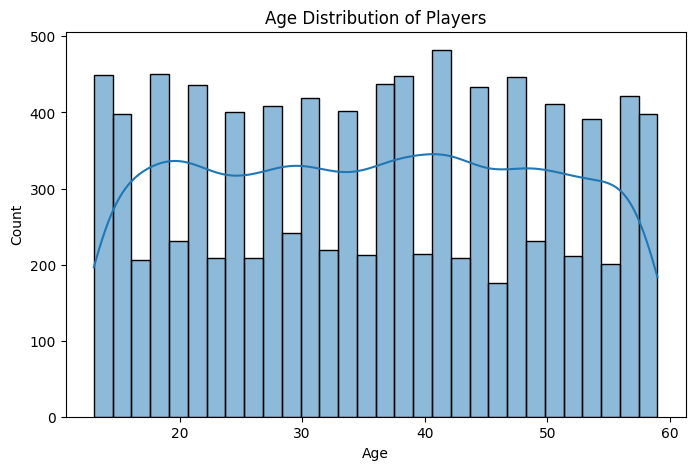

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df_sample["age"], bins=30, kde=True)

plt.title("Age Distribution of Players")
plt.xlabel("Age")
plt.ylabel("Count")

plt.show()


Findings
- The dataset includes players ranging approximately from 13 to 59 years old.
- The distribution appears fairly uniform, suggesting that the dataset was likely generated or sampled to represent players across many age groups.
- There is no strong concentration in a specific age range.

### 4.3 Gaming Hours Distribution
Analyze the distribution of players' daily gaming hours

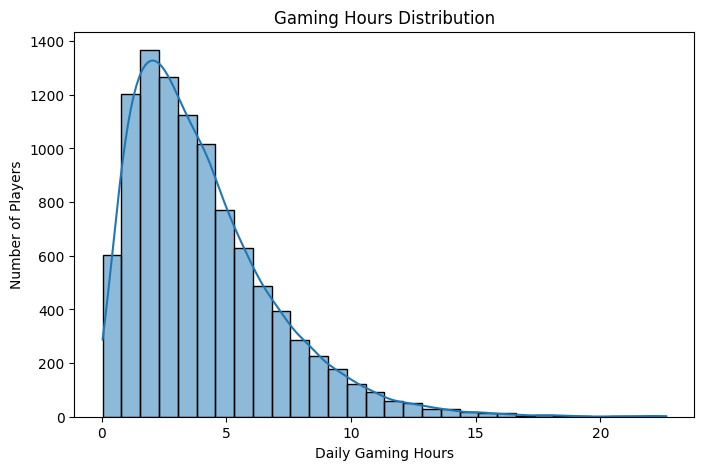

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df_sample["daily_gaming_hours"], bins=30, kde=True)

plt.title("Gaming Hours Distribution")
plt.xlabel("Daily Gaming Hours")
plt.ylabel("Number of Players")

plt.show()

Findings
- Most players spend between 1 and 5 hours gaming per day.
- The distribution is right-skewed, meaning a small number of players spend significantly more time gaming.
- A few extreme cases show players gaming more than 15 hours per day, which may represent heavy gamers.

### 4.4 Correlation Analysis
Analyze the relationships between gaming habits, mental health scores, and lifestyle factors.

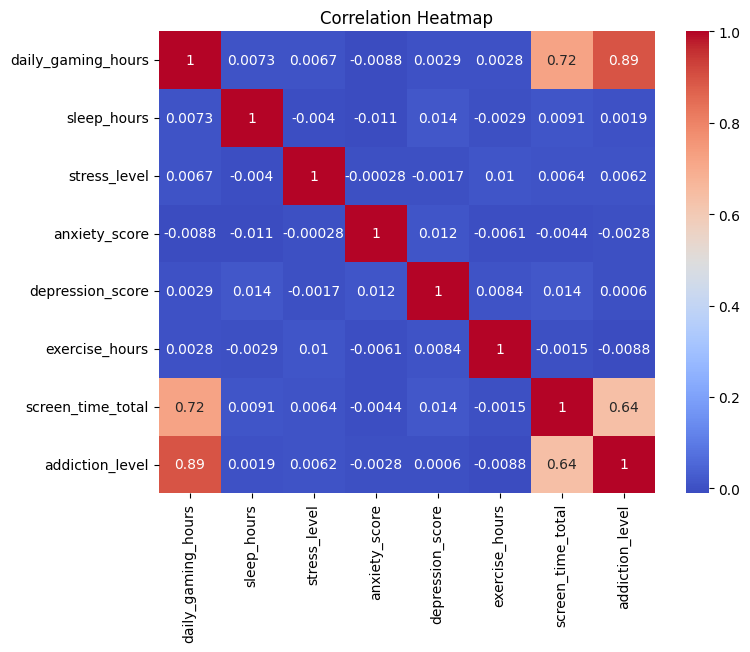

In [ ]:
corr_cols = [
    "daily_gaming_hours",
    "sleep_hours",
    "stress_level",
    "anxiety_score",
    "depression_score",
    "exercise_hours",
    "screen_time_total",
    "addiction_level"
]

plt.figure(figsize=(8,6))

sns.heatmap(
    df_sample[corr_cols].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

Findings
- Strong Positive Correlations: daily_gaming_hours shows strong correlations with addiction_level (0.89) and screen_time_total (0.72).
- Weak Mental Health Relationships: Variables such as stress_level, anxiety_score, and depression_score show near-zero correlation with gaming hours.
- Lifestyle Independence: exercise_hours and sleep_hours show little to no correlation with gaming or mental health metrics.

### 4.5 Gaming Hours vs Addiction Level

Analyze the relationship between gaming time and addiction level.

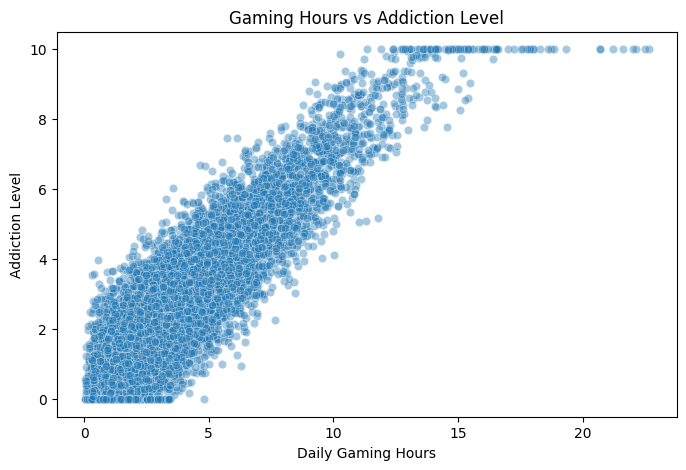

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x=df_sample["daily_gaming_hours"],
    y=df_sample["addiction_level"],
    alpha=0.4
)

plt.title("Gaming Hours vs Addiction Level")
plt.xlabel("Daily Gaming Hours")
plt.ylabel("Addiction Level")

plt.show()

Findings
- Strong Positive Relationship: There is a clear positive relationship between daily gaming hours and addiction level, confirming the high correlation observed in the correlation analysis.
- Addiction Ceiling Effect: Players who exceed roughly 12–15 hours of gaming per day often reach the maximum addiction score (10).
- Lower Addiction at Moderate Play: Most players who game between 0 and 5 hours per day show relatively low addiction scores.

## 5- Key Insights
Summary of the most important findings discovered during the exploratory data analysis.
- Moderate Gaming Behavior: Most players spend between 1 and 5 hours per day gaming, indicating that extreme gaming habits are relatively uncommon in the dataset.
- Gaming Time and Addiction: A strong positive correlation exists between daily gaming hours and addiction level, suggesting that increased gaming time is closely associated with higher addiction scores.
- Weak Links to Mental Health Metrics: Variables such as stress, anxiety, and depression show little to no correlation with gaming hours in this dataset.
- Lifestyle Factors Appear Independent: Sleep and exercise habits do not show meaningful linear relationships with gaming behavior or mental health scores.

## 6- Final Conclusion

Key findings from the exploratory analysis:

- Most players spend 1–5 hours per day gaming, suggesting moderate gaming behavior.
- Daily gaming hours strongly correlate with addiction level, indicating that increased gaming time is associated with higher addiction scores.
- Mental health indicators (stress, anxiety, depression) show weak correlations with gaming hours in this dataset.
- Lifestyle variables such as sleep and exercise appear largely independent from gaming habits.

Overall, the analysis suggests that gaming intensity may influence addiction patterns, but its direct relationship with mental health is unclear in this dataset.